# Dry Bean Decision Trees

## Imports

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

## a) Load dataset
- Source: [(https://archive.ics.uci.edu/dataset/602/dry+bean+dataset)]

This dataset contains 13,611 images of seven bean varieties, with 16 features including `Area`, `Perimeter`, `MajorAxisLength`, `MinorAxisLength`, ect... The target column is `Class`, which corresponds to the bean variety. We check for missing values, and inspect the class proportions.

In [8]:
# load dry bean dataset from UCI ML repository
beans = fetch_ucirepo(id=602)
df = pd.concat([beans.data.features, beans.data.targets], axis=1)

print(f"Total missing values in the dataset: {df.isna().sum().sum()}")

# summarize class counts and proportions in a table
class_summary = (
    df["Class"]
    .value_counts()
    .rename_axis("Class")
    .reset_index(name="Count"))
class_summary["Proportion"] = class_summary["Count"] / len(df)
display(class_summary)

Total missing values in the dataset: 0

Class counts and proportions:


,Class,Count,Proportion
0,DERMASON,3546,0.260525
1,SIRA,2636,0.193667
2,SEKER,2027,0.148924
3,HOROZ,1928,0.141650
4,CALI,1630,0.119756
5,BARBUNYA,1322,0.097127
6,BOMBAY,522,0.038351


Now, we split the data into training, validation, and testing datasets. Then, we will check the class counts and proportions again, this time for each dataset.

In [10]:
X = df.drop(columns="Class")
y = df["Class"]
X_tr, X_val, y_tr, y_val = train_test_split(X, y, stratify=y, random_state=42)

# Create testing split
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Separate training and validation split
X_tr, X_val, y_tr, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# summarize class counts and proportions for each split
for split_name, y_split in [
    ("Training", y_tr),
    ("Validation", y_val),
    ("Testing", y_test)]:
    
    summary = (
        y_split.value_counts()
        .rename_axis("Class")
        .reset_index(name="Count")
        .sort_values("Class")
    )
    summary["Proportion"] = summary["Count"] / len(y_split)

    print(f"\n{split_name} dataset class distribution:")
    display(summary)


Training dataset class distribution:


,Class,Count,Proportion
5,BARBUNYA,793,0.097110
6,BOMBAY,313,0.038330
4,CALI,978,0.119765
0,DERMASON,2128,0.260593
3,HOROZ,1156,0.141563
2,SEKER,1216,0.148910
1,SIRA,1582,0.193730



Validation dataset class distribution:


,Class,Count,Proportion
5,BARBUNYA,264,0.096988
6,BOMBAY,105,0.038575
4,CALI,326,0.119765
0,DERMASON,709,0.260470
3,HOROZ,386,0.141807
2,SEKER,405,0.148788
1,SIRA,527,0.193608



Testing dataset class distribution:


,Class,Count,Proportion
5,BARBUNYA,265,0.097319
6,BOMBAY,104,0.038193
4,CALI,326,0.119721
0,DERMASON,709,0.260375
3,HOROZ,386,0.141755
2,SEKER,406,0.149100
1,SIRA,527,0.193537


The `stratify=y` parameter keeps the class proportions in `y` roughly the same in the training, testing, and validation sets. This is important because we want to make sure all classes are adequetly represented in each dataset. This is especially useful when classes are imbalanced.

## b) Unrestricted decision tree
- Source: [(https://www.geeksforgeeks.org/machine-learning/decision-tree-implementation-python/)]

A decision tree is a supervised machine learning algorithm used for both classification and regression. It uses a tree-like structure where:
- Nodes represent decisions or feature tests.
- Branches represent outcomes of those decisions/tests.
- Lead nodes represent final predictions or class labels.

A decision tree is trained according to the following algorithm:
1. Start with full dataset at root node.
2. Select best feature using splitting criterion.
3. Split data into subsets.
4. Continue recursively until stopping conditions are met.
5. Assign class labels at lead nodes.

Splitting criterion include Gini Index, Entropy, and Information gain.

First, we create an unrestricted decision tree, which can have any number of nodes and branches.

In [12]:
tree = DecisionTreeClassifier(random_state=42, min_samples_leaf=1)
tree.fit(X_tr, y_tr)

y_tr_pred = tree.predict(X_tr)
y_val_pred = tree.predict(X_val)

print(f"depth={tree.get_depth()}, leaves={tree.get_n_leaves()}")
print(f"train_acc={accuracy_score(y_tr, y_tr_pred):.4f}")
print(f"val_acc={accuracy_score(y_val, y_val_pred):.4f}")
print(f"val_macro_f1={f1_score(y_val, y_val_pred, average='macro'):.4f}")

depth=30, leaves=552
train_acc=1.0000
val_acc=0.8997
val_macro_f1=0.9118


We see the model fits the training data perfectly, with a training accuracy of 1.00. However, the validation accuracy is 0.8924 and the validation macro F1 is 0.9089. This suggests slight overfitting, as the model memorizes the training set better than it generalizes to new data. Overall, the model is still performing well.

## c) Restricted decision trees

Now we try fitting a restricted decision tree with a given maximum depth. 

In [13]:
depths = [2, 4, 6, 8, 12, None]
rows = []

for d in depths:
    tree = DecisionTreeClassifier(random_state=42, max_depth=d)
    tree.fit(X_tr, y_tr)

    y_tr_pred = tree.predict(X_tr)
    y_val_pred = tree.predict(X_val)

    rows.append({
        "max_depth": d,
        "train_acc": accuracy_score(y_tr, y_tr_pred),
        "val_acc": accuracy_score(y_val, y_val_pred),
        "val_macro_f1": f1_score(y_val, y_val_pred, average="macro"),
    })

results = pd.DataFrame(rows)
display(results)

,max_depth,train_acc,val_acc,val_macro_f1
0,2.0,0.654666,0.659809,0.457679
1,4.0,0.826108,0.834680,0.765907
2,6.0,0.913177,0.908523,0.915702
3,8.0,0.939750,0.912932,0.921364
4,12.0,0.983223,0.904482,0.917364
5,NaN,1.000000,0.899706,0.911845


The results show that deeper trees improve training accuracy. However, validation performance peaks at around depth 8, and then drops. At depth 12, the training accuracy increases even further, but validation accuracy and F1 decrease. Similarly for the unrestricted tree, training accuracy reaches 1.00, but validation accuracy and F1 decrease. We see underfitting at depths less than 8, and overfitting at depths greater than 8.

Next, we plot the training and validation accuracy against the finite depth value. Because the unrestricted tree has a max depth of `NaN`, it must be shown separately.

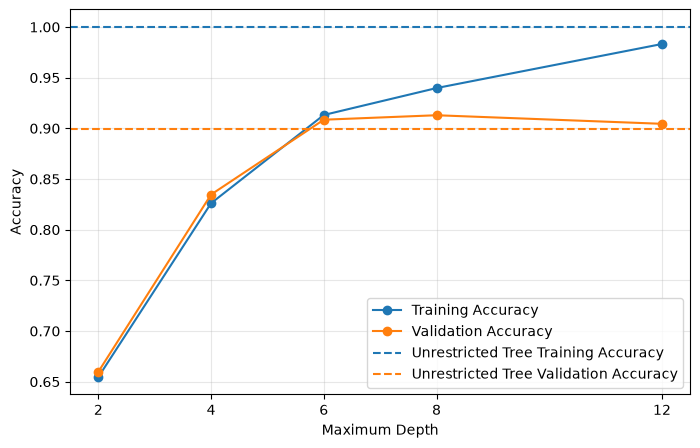

In [15]:
res = results.dropna(subset=["max_depth"]).copy() # Copy column, remove unrestricted tree
res["max_depth"] = res["max_depth"].astype(int)
unres = results[results["max_depth"].isna()].iloc[0] # Get unrestricted tree

plt.figure(figsize=(8, 5))
plt.plot(res["max_depth"], res["train_acc"], marker="o", label="Training Accuracy")
plt.plot(res["max_depth"], res["val_acc"], marker="o", label="Validation Accuracy")
plt.axhline(unres["train_acc"], color="C0", linestyle="--", label="Unrestricted Tree Training Accuracy") 
plt.axhline(unres["val_acc"], color="C1", linestyle="--", label="Unrestricted Tree Validation Accuracy")
plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.xticks(res["max_depth"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The plot shows that as `max_depth` increases, training accuracy rises constistently,. However, validation accuracy only improves until about depth 8. The best balance is around `max_depth=8` where validation accuracy is highest. After that, the model does not generalize as well. This suggests overfitting.

## d) Random Forest
- Source: [(https://www.geeksforgeeks.org/random-forest-classifier-using-scikit-learn/)]

A Random Forest is an ensemble learning method that combines multiple decision trees to produce more stable and accurate predictions. For regression problems, the output of several trees are averaged. For classification problems, Majority Voting is used.

The Random Forest Classifier uses Bootstrap Sampling: Random rows are picked to train each tree, and each row is put back in the pool after being picked, so it can be picked more than onece. It uses Random Feature Selection, meaning each tree uses a random subset of features.

We fit four Random Forest Classifiers with 200 trees each and bootstrap sampling enabled. We compare four different settings combinations.

In [16]:
settings = [
    {"max_depth": 8, "min_samples_leaf": 1},
    {"max_depth": 8, "min_samples_leaf": 5},
    {"max_depth": None, "min_samples_leaf": 1},
    {"max_depth": None, "min_samples_leaf": 5}]

rows = []

for params in settings:
    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        bootstrap=True,
        max_depth=params["max_depth"],
        min_samples_leaf=params["min_samples_leaf"],
        max_features="sqrt")
    rf.fit(X_tr, y_tr)

    y_tr_pred = rf.predict(X_tr)
    y_val_pred = rf.predict(X_val)

    rows.append({
        "max_depth": params["max_depth"],
        "min_samples_leaf": params["min_samples_leaf"],
        "train_acc": accuracy_score(y_tr, y_tr_pred),
        "val_acc": accuracy_score(y_val, y_val_pred),
        "val_macro_f1": f1_score(y_val, y_val_pred, average="macro"),
    })

results = pd.DataFrame(rows)
display(results)

,max_depth,min_samples_leaf,train_acc,val_acc,val_macro_f1
0,8.0,1,0.945628,0.928729,0.938194
1,8.0,5,0.935464,0.925790,0.934278
2,NaN,1,1.000000,0.931668,0.941246
3,NaN,5,0.960078,0.930566,0.940087


The best-performing forest is the one with `max_depth = None` and `min_samples_leaf = 1`. 

The unrestricted forest fits the training data perfectly, and generalizes well to the validation set. The macro F1 score, which accounts for performance across all classes, is also strong. The random forest performs better than the single decision tree. Overfitting is limit compares with the deeper single tree.

In [9]:
candidate = results.copy()

# Treat unrestricted trees as the deepest option so finite depths win ties
candidate["depth_rank"] = candidate["max_depth"].apply(
    lambda x: float("inf") if pd.isna(x) else int(x))

best_row = candidate.sort_values(
    ["val_macro_f1", "depth_rank", "min_samples_leaf"],
    ascending=[False, True, False],
    kind="mergesort").iloc[0]

best_depth = None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"])
best_min_samples_leaf = int(best_row["min_samples_leaf"])

print(f"Selected max_depth: {best_depth}")
print(f"Selected min_samples_leaf: {best_min_samples_leaf}")
print(f"Best validation macro-F1: {best_row['val_macro_f1']:.4f}")

best_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    bootstrap=True,
    max_depth=best_depth,
    min_samples_leaf=best_min_samples_leaf,
    max_features="sqrt",)
best_rf.fit(X_tr, y_tr)

y_val_pred_best = best_rf.predict(X_val)
print(f"Final validation macro-F1: {f1_score(y_val, y_val_pred_best, average='macro'):.4f}")

Selected max_depth: None
Selected min_samples_leaf: 1
Best validation macro-F1: 0.9341
Final validation macro-F1: 0.9341


The selected model has `max_depth = None` and `min_samples_leaf = 1` and achieves final validation macro-F1 of 0.9341. The model-selection step correctly identified the best-performing random forest. When that random forest configuration was fit again on the training data, it produced the same validation performance. 

## e) 

In [10]:
# If a true untouched test split has not yet been created, reserve one from the full data.
if "X_test" not in globals() or "y_test" not in globals():
    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42)
    
    # Rebuild the train/validation split used for model selection if needed.
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# Refit all candidate models on the combined training + validation data.
X_train_all = pd.concat([X_tr, X_val], axis=0)
y_train_all = pd.concat([y_tr, y_val], axis=0)

# 1) unrestricted tree
tree_unres = DecisionTreeClassifier(random_state=42)
tree_unres.fit(X_train_all, y_train_all)

# 2) selected depth-controlled tree (from earlier validation-based selection)
tree_selected = DecisionTreeClassifier(
    random_state=42,
    max_depth=best_tree.get_params()["max_depth"])
tree_selected.fit(X_train_all, y_train_all)

# 3) selected random forest (from earlier validation-based selection)
rf_selected = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    bootstrap=True,
    max_depth=best_rf.get_params()["max_depth"],
    min_samples_leaf=best_rf.get_params()["min_samples_leaf"],
    max_features="sqrt")
rf_selected.fit(X_train_all, y_train_all)

models = {
    "unrestricted_tree": tree_unres,
    "selected_depth_tree": tree_selected,
    "selected_random_forest": rf_selected}

rows = []
for model_name, model in models.items():
    y_pred = model.predict(X_test)
    rows.append({
        "model": model_name,
        "test_acc": accuracy_score(y_test, y_pred),
        "test_macro_f1": f1_score(y_test, y_pred, average="macro")})

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))

                 model  test_acc  test_macro_f1
     unrestricted_tree  0.891664       0.908493
   selected_depth_tree  0.903415       0.915369
selected_random_forest  0.921043       0.932582


These results show the selected random forest is the best model on the test set. It has the highest accuracy and the highest macro-F1, which means it classifies bean types most accurately overall and also performs best across classes. The selected depth-controlled tree is better than the unrestricted tree, which indicates that the validation-based depth choice reduced overfitting. The unrestricted tree still performs reasonably well, but is worse than the tuned tree and the random forest.

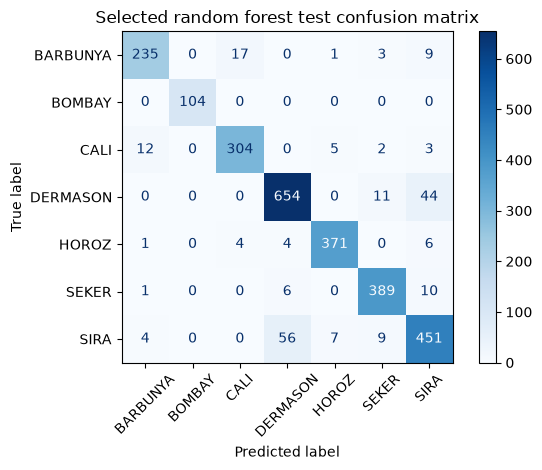

In [12]:
y_test_pred = rf_selected.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred, labels=rf_selected.classes_)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rf_selected.classes_)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Selected random forest test confusion matrix")
plt.tight_layout()
plt.show()

The confusion matrix shows how the selected random forest performed on the test set across the seven bean classes. Most observations fall on the diagonal, meaning the model is correctly classifying most bean types. The darker blue cells indicate stronger predictions. Some classes are more difficult to classify than others. The errors are not randomly distributed but are concentrated in visually similar bean classes. This further shows that the random forest is a strong model.